# Movie-review sentiment with a bidirectional LSTM

Classify individual IMDb review excerpts as positive or negative and inspect the reading workload created by negative predictions. The tab-separated source contains 1,000 labeled reviews. Quotation marks are literal review text. Remove exact duplicate text/label pairs and keep identical cleaned texts in one split. Split the records before fitting the vocabulary, then evaluate the selected model once on the held-out test set.

The model keeps the 100-dimensional embedding, 128-unit BiLSTM, 64-unit dense layer, dropout, 50-token limit and early-stopping approach. These movie-review results need independent validation before use on customer-support messages.

## Configure the numerical environment

In [2]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import csv, json, re
from pathlib import Path
import importlib.metadata as package_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
DATA = Path("../data")
ASSETS = Path("../assets")
MODELS = Path("../models")
for directory in [ASSETS, MODELS]:
    directory.mkdir(exist_ok=True)
try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", raise_on_error=True)
    stop_words = set(stopwords.words("english"))
print("Python packages:", {name: package_metadata.version(name) for name in
      ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "tensorflow", "keras", "nltk"]})

Python packages: {'numpy': '2.2.2', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'scikit-learn': '1.6.1', 'tensorflow': '2.20.0', 'keras': '3.12.0', 'nltk': '3.9.2'}


## Load and validate individual reviews

In [3]:
df = pd.read_csv(DATA / "imdb_labelled.txt", sep="\t", header=None,
                 names=["text", "label"], quoting=csv.QUOTE_NONE, encoding="utf-8")
assert len(df) == 1000
assert df.notna().all().all()
assert set(df["label"].unique()) == {0, 1}
assert not df["text"].str.contains(r"[\t\r\n]", regex=True).any()
df.index.name = "source_row"
print("Reviews:", len(df))
print("Class counts:", df["label"].value_counts().sort_index().to_dict())

Reviews: 1000
Class counts: {0: 500, 1: 500}


## Clean text and create grouped splits

Cleaning lowercases text, removes URLs, HTML and punctuation, and removes English stopwords. Three exact duplicate text/label pairs are excluded. Ten stratified group folds keep identical cleaned texts together: fold 0 is test, fold 1 is validation, and the other eight are training. This gives approximately 80/10/10 partitions without sharing identical model-input text across them. The tokenizer sees training text only.

In [4]:
def clean_text(text):
    text = re.sub(r"http\S+|www\S+", " ", str(text).lower())
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return " ".join(word for word in text.split() if word not in stop_words)

df["clean_text"] = df["text"].apply(clean_text)
source_reviews = len(df)
df = df.drop_duplicates(subset=["text", "label"]).copy()
group_split = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = list(group_split.split(df["clean_text"], df["label"], groups=df["clean_text"]))
test_rows = df.index.to_numpy()[folds[0][1]]
val_rows = df.index.to_numpy()[folds[1][1]]
train_rows = df.index[~df.index.isin(np.concatenate([val_rows, test_rows]))].to_numpy()
assert not set(train_rows) & set(val_rows) and not set(train_rows) & set(test_rows)
assert not set(val_rows) & set(test_rows)
for first, second in [(train_rows, val_rows), (train_rows, test_rows), (val_rows, test_rows)]:
    assert not set(df.loc[first, "clean_text"]) & set(df.loc[second, "clean_text"])
print("Rows after exact deduplication:", len(df))
print("Training / validation / test:", len(train_rows), len(val_rows), len(test_rows))
for name, rows in [("train", train_rows), ("validation", val_rows), ("test", test_rows)]:
    print(name, df.loc[rows, "label"].value_counts().sort_index().to_dict())

Rows after exact deduplication: 997
Training / validation / test: 799 100 98
train {0: 388, 1: 411}
validation {0: 57, 1: 43}
test {0: 54, 1: 44}


## Fit the training vocabulary and inspect sequence lengths

The tokenizer learns only from training reviews. Unknown words in validation or test text map to the out-of-vocabulary token. The 50-token input limit is retained; coverage below describes the training reviews, without using held-out text to choose the length.

Vocabulary size including padding: 2540
Training length min / median / max: 1 6.0 44
Training reviews covered by 50 tokens: 100.00%


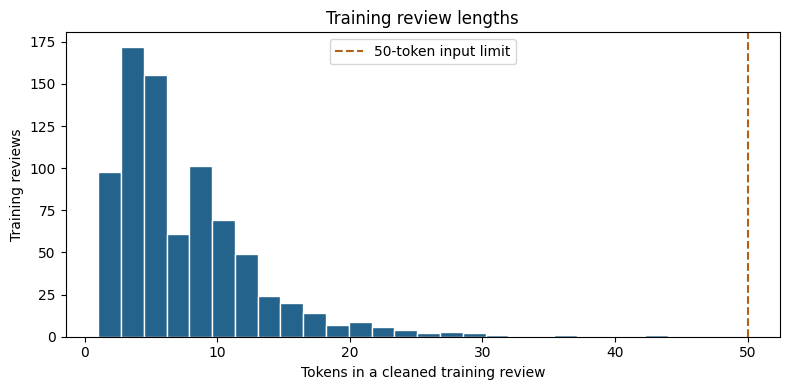

In [5]:
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(df.loc[train_rows, "clean_text"])
max_sequence_len = 50
vocab_size = len(tokenizer.word_index) + 1
train_sequences = tokenizer.texts_to_sequences(df.loc[train_rows, "clean_text"])
training_lengths = np.array([len(seq) for seq in train_sequences])
coverage = float(np.mean(training_lengths <= max_sequence_len) * 100)
print("Vocabulary size including padding:", vocab_size)
print("Training length min / median / max:", training_lengths.min(), np.median(training_lengths), training_lengths.max())
print(f"Training reviews covered by 50 tokens: {coverage:.2f}%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(training_lengths, bins=25, color="#24638b", edgecolor="white")
ax.axvline(max_sequence_len, color="#b45f17", linestyle="--", label="50-token input limit")
ax.set(xlabel="Tokens in a cleaned training review", ylabel="Training reviews", title="Training review lengths")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "review-lengths.png", dpi=160)
plt.show()

In [6]:
def encode_rows(rows):
    sequences = tokenizer.texts_to_sequences(df.loc[rows, "clean_text"])
    return pad_sequences(sequences, maxlen=max_sequence_len, padding="post", truncating="post")

X_train, X_val, X_test = [encode_rows(rows) for rows in [train_rows, val_rows, test_rows]]
y_train, y_val, y_test = [df.loc[rows, "label"].to_numpy() for rows in [train_rows, val_rows, test_rows]]
for name, X, y in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    split = pd.DataFrame(X, columns=[str(i) for i in range(max_sequence_len)])
    split["label"] = y
    split.to_csv(DATA / f"{name}_dataset.csv", index=False)
print("Encoded split shapes:", X_train.shape, X_val.shape, X_test.shape)

Encoded split shapes: (799, 50) (100, 50) (98, 50)


## Build and train the BiLSTM

Validation loss selects the stopping point; the test set is not used for fitting or epoch selection. Training uses a fixed seed and deterministic TensorFlow operations. Different numerical environments can still produce different fitted weights.

In [7]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=100),
    Bidirectional(LSTM(128, return_sequences=False)),
    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_sequence_len))
model.summary()
early_stopping = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

options = tf.data.Options()
options.threading.private_threadpool_size = 1
train_data = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(
    len(X_train), seed=SEED, reshuffle_each_iteration=True).batch(32).with_options(options)
val_data = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(32).with_options(options)
history = model.fit(train_data, epochs=15, validation_data=val_data,
                    callbacks=[early_stopping], verbose=2)
history_frame = pd.DataFrame(history.history)
history_frame.index = pd.RangeIndex(1, len(history_frame) + 1, name="epoch")
history_frame.to_csv(DATA / "training_history.csv")
best_epoch = int(history_frame["val_loss"].idxmin())
print("Epochs completed:", len(history_frame), "Best validation-loss epoch:", best_epoch)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │       254,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 505,009 (1.93 MB)

 Trainable params: 505,009 (1.93 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


... (6 outputs left out)

25/25 - 1s - 29ms/step - accuracy: 0.9312 - loss: 0.1800 - val_accuracy: 0.7400 - val_loss: 0.5601


Epoch 5/15


25/25 - 1s - 30ms/step - accuracy: 0.9762 - loss: 0.0867 - val_accuracy: 0.7800 - val_loss: 0.5185


Epochs completed: 5 Best validation-loss epoch: 3


## Inspect training and held-out performance

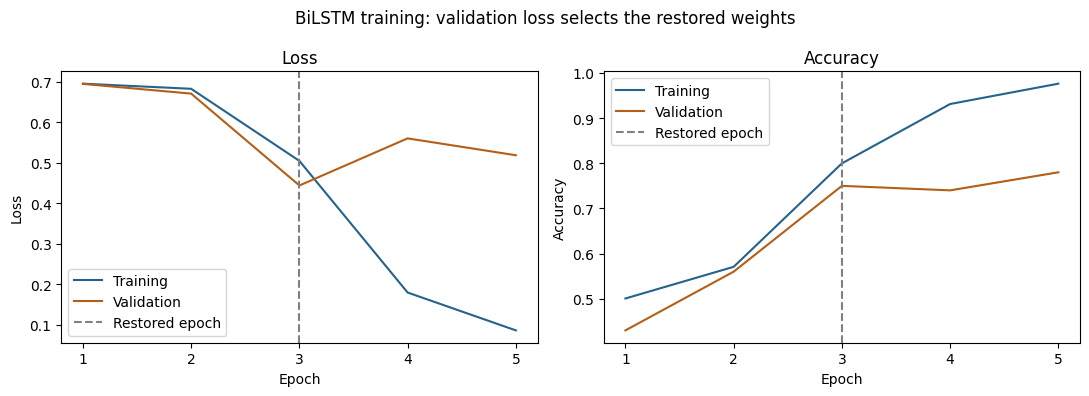

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(history_frame.index, history_frame[metric], label="Training", color="#24638b")
    ax.plot(history_frame.index, history_frame["val_" + metric], label="Validation", color="#b45f17")
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Restored epoch")
    ax.set(xlabel="Epoch", ylabel=title, title=title)
    ax.set_xticks(history_frame.index)
    ax.legend()
fig.suptitle("BiLSTM training: validation loss selects the restored weights")
fig.tight_layout()
fig.savefig(ASSETS / "training-history.png", dpi=160)
plt.show()

{
  "source_reviews": 1000,
  "modeling_reviews": 997,
  "exact_duplicates_removed": 3,
  "train_reviews": 799,
  "validation_reviews": 100,
  "test_reviews": 98,
  "seed": 42,
  "threshold": 0.5,
  "accuracy": 0.7857142857142857,
  "positive_precision": 0.7254901960784313,
  "positive_recall": 0.8409090909090909,
  "positive_f1": 0.7789473684210526,
  "confusion_matrix": [
    [
      40,
      14
    ],
    [
      7,
      37
    ]
  ],
  "training_coverage_percent": 100.0,
  "vocabulary_size": 2540,
  "epochs_completed": 5,
  "best_epoch": 3
}
              precision    recall  f1-score   support

    Negative     0.8511    0.7407    0.7921        54
    Positive     0.7255    0.8409    0.7789        44

    accuracy                         0.7857        98
   macro avg     0.7883    0.7908    0.7855        98
weighted avg     0.7947    0.7857    0.7862        98



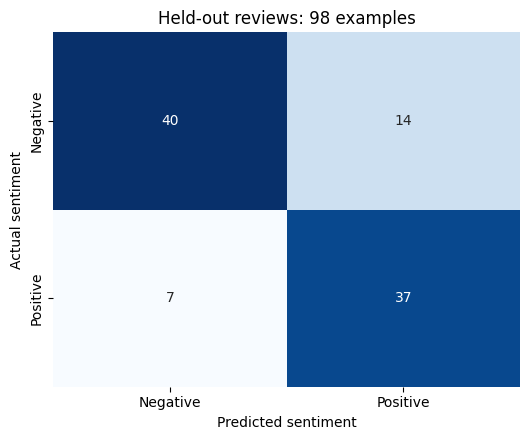

In [9]:
y_prob = model(X_test, training=False).numpy().reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
metrics = {
    "source_reviews": source_reviews, "modeling_reviews": len(df), "exact_duplicates_removed": source_reviews - len(df),
    "train_reviews": len(X_train), "validation_reviews": len(X_val),
    "test_reviews": len(X_test), "seed": SEED, "threshold": 0.5,
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "positive_precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "positive_recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "positive_f1": float(f1_score(y_test, y_pred, zero_division=0)),
    "confusion_matrix": cm.tolist(), "training_coverage_percent": coverage,
    "vocabulary_size": vocab_size, "epochs_completed": len(history_frame), "best_epoch": best_epoch,
}
(DATA / "evaluation_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
pd.DataFrame({"source_row": test_rows, "actual": y_test, "positive_probability": y_prob,
              "predicted": y_pred}).to_csv(DATA / "test_predictions.csv", index=False)
print(json.dumps(metrics, indent=2))
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(5.4, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"], ax=ax)
ax.set(xlabel="Predicted sentiment", ylabel="Actual sentiment", title=f"Held-out reviews: {len(y_test)} examples")
fig.tight_layout()
fig.savefig(ASSETS / "sentiment-test-confusion.png", dpi=160)
plt.show()

## Interpret the review queue

Negative predictions form a possible manual-review queue. Its size, caught negatives and positive reviews sent for review describe workload on this test set. Movie reviews do not establish performance on support tickets. The small test set provides a limited estimate; a larger independent evaluation is needed before an operational trial.

In [10]:
tn, fp, fn, tp = cm.ravel()
print(f"Negative-review queue: {tn + fn} of {len(y_test)} reviews")
print(f"Caught negative reviews: {tn} of {tn + fp}")
print(f"Positive reviews in that queue: {fn}")
print(f"Missed negative reviews: {fp}")

Negative-review queue: 47 of 98 reviews
Caught negative reviews: 40 of 54
Positive reviews in that queue: 7
Missed negative reviews: 14


## Export and verify the model with its tokenizer

The Keras file accepts padded token IDs. The accompanying tokenizer and preprocessing metadata define how raw text becomes that input. Reloading both artifacts below must reproduce the held-out probabilities and predictions.

In [11]:
model_path = MODELS / "imdb_sentiment_bilstm_model.keras"
model.save(model_path)
(MODELS / "tokenizer.json").write_text(tokenizer.to_json(), encoding="utf-8")
(MODELS / "preprocessing.json").write_text(json.dumps({
    "max_sequence_length": max_sequence_len, "padding": "post", "truncating": "post",
    "threshold": 0.5, "negative_label": 0, "positive_label": 1,
    "stopword_language": "english", "nltk_version": package_metadata.version("nltk"),
    "english_stopwords": sorted(stop_words),
    "vocabulary_fitted_on": "training reviews only", "seed": SEED,
}, indent=2), encoding="utf-8")
restored_tokenizer = tokenizer_from_json((MODELS / "tokenizer.json").read_text(encoding="utf-8"))
restored_X = pad_sequences(restored_tokenizer.texts_to_sequences(df.loc[test_rows, "clean_text"]),
                          maxlen=max_sequence_len, padding="post", truncating="post")
np.testing.assert_array_equal(restored_X, X_test)
restored_model = load_model(model_path, compile=False)
restored_probabilities = restored_model(restored_X, training=False).numpy().reshape(-1)
np.testing.assert_allclose(restored_probabilities, y_prob, atol=1e-7, rtol=1e-6)
np.testing.assert_array_equal((restored_probabilities >= 0.5).astype(int), y_pred)
print("Reloaded model and tokenizer reproduce all held-out predictions.")

Reloaded model and tokenizer reproduce all held-out predictions.
